# LassoSelector: speed and reproducibility

This notebook times LassoSelector against scikit-learn's liblinear and
checks that every fit gives the same genes. It ends with a verdict per
dataset: which is faster, and by how much.

**Variants.**

- **scikit-learn**: LogisticRegression(l1_ratio=1, solver='liblinear',
  C=1), its default tolerance 1e-4.
- **featsel PPDNA, CPU** and **featsel PPDNA, GPU**: LassoSelector with
  device='cpu' or 'cuda'. The same L1 logistic regression solved to a
  tight tolerance (see `ppdna.py`).

**Agreement.** PPDNA matches liblinear run to a tight tolerance (the tests
check this). liblinear's default tolerance stops early and keeps slightly
different genes, so `jaccard_vs_original` is near 1 but not 1.

**Data.**

1. Synthetic, shaped like SCAN-B: 3,000 patients, one in five positive, 50
   informative genes among 30,000. Each variant fits on the first 1,000,
   3,000, 10,000 and 30,000 genes.
2. SCAN-B (GSE96058): all 2,976 patients and all genes, standardized as the
   experiments do. The five PAM50 tasks, each subtype against the rest, are
   five binary datasets.

**Each row of a table.** One variant on one dataset:

- `median_s`, `min_s`, `max_s`: seconds per fit, over 2 timed fits after
  one untimed fit (CUDA starts then).
- `reproducible`: every fit, the untimed one included, chose the same genes.
- `jaccard_vs_original`: overlap of its genes with liblinear's.

Times hold for this machine only. The JSON written beside each CSV records it.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

import featsel
from featsel import benchmark, environment
from featsel.run import build_tasks

NAME = 'LassoSelector'
OUT = Path(featsel.__file__).parents[1] / 'results' / 'local' / 'speed'
OUT.mkdir(parents=True, exist_ok=True)


def verdict(table, key):
    """Per dataset: each variant's time and speed against liblinear's."""
    for name, part in table.groupby(key, sort=False):
        original = part.iloc[0]
        for _, row in part.iloc[1:].iterrows():
            ratio = original['median_s'] / row['median_s']
            faster = f"{ratio:.1f}x faster" if ratio >= 1 else f"{1 / ratio:.1f}x slower"
            print(f"{name!s:>12}: {row['variant']} {row['median_s']:.2f} s, "
                  f"liblinear {original['median_s']:.2f} s -> {faster}; "
                  f"reproducible {bool(part['reproducible'].all())}, "
                  f"Jaccard {row['jaccard_vs_original']:.3f}")


print(f"Memory cap: {benchmark.cap_memory():.1f} GB")
print("Variants:", ', '.join(benchmark.variants(NAME)))

Memory cap: 7.7 GB


Variants: scikit-learn, featsel PPDNA, CPU, featsel PPDNA, GPU


## 1. Synthetic data, growing gene counts

In [2]:
X, y = benchmark.synthetic()
print(f"{X.shape[0]} patients x {X.shape[1]} genes, {y.sum()} positive")
table = benchmark.benchmark(NAME, X, y)
table.to_csv(OUT / f'{NAME}.csv', index=False)
environment.write_json((OUT / f'{NAME}.csv').with_suffix('.json'), selector=NAME,
                       params=benchmark.PARAMS[NAME], n_patients=int(X.shape[0]))
table.round(4)

3000 patients x 30000 genes, 603 positive


,variant,device,n_genes,n_patients,fits,median_s,min_s,max_s,n_selected,reproducible,jaccard_vs_original
0,scikit-learn,cpu,1000,3000,3,0.8098,0.8008,0.8187,948,True,1.0000
1,scikit-learn,cpu,3000,3000,3,2.2958,2.0306,2.5610,1466,True,1.0000
2,scikit-learn,cpu,10000,3000,3,2.8073,2.6921,2.9226,1662,True,1.0000
3,scikit-learn,cpu,30000,3000,3,5.4772,5.4298,5.5246,1330,True,1.0000
4,"featsel PPDNA, CPU",cpu,1000,3000,3,2.1844,2.0606,2.3082,948,True,1.0000
5,"featsel PPDNA, CPU",cpu,3000,3000,3,4.4391,4.3563,4.5219,1466,True,0.9973
6,"featsel PPDNA, CPU",cpu,10000,3000,3,23.4209,23.2427,23.5991,1662,True,0.9809
7,"featsel PPDNA, CPU",cpu,30000,3000,3,26.6205,25.8996,27.3414,1322,True,0.9093
8,"featsel PPDNA, GPU",cuda,1000,3000,3,0.4082,0.4074,0.4090,948,True,1.0000
9,"featsel PPDNA, GPU",cuda,3000,3000,3,0.6541,0.6391,0.6690,1466,True,0.9973


In [3]:
verdict(table, 'n_genes')

        1000: featsel PPDNA, CPU 2.18 s, liblinear 0.81 s -> 2.7x slower; reproducible True, Jaccard 1.000
        1000: featsel PPDNA, GPU 0.41 s, liblinear 0.81 s -> 2.0x faster; reproducible True, Jaccard 1.000
        3000: featsel PPDNA, CPU 4.44 s, liblinear 2.30 s -> 1.9x slower; reproducible True, Jaccard 0.997
        3000: featsel PPDNA, GPU 0.65 s, liblinear 2.30 s -> 3.5x faster; reproducible True, Jaccard 0.997
       10000: featsel PPDNA, CPU 23.42 s, liblinear 2.81 s -> 8.3x slower; reproducible True, Jaccard 0.981
       10000: featsel PPDNA, GPU 0.94 s, liblinear 2.81 s -> 3.0x faster; reproducible True, Jaccard 0.981
       30000: featsel PPDNA, CPU 26.62 s, liblinear 5.48 s -> 4.9x slower; reproducible True, Jaccard 0.909
       30000: featsel PPDNA, GPU 0.99 s, liblinear 5.48 s -> 5.5x faster; reproducible True, Jaccard 0.909


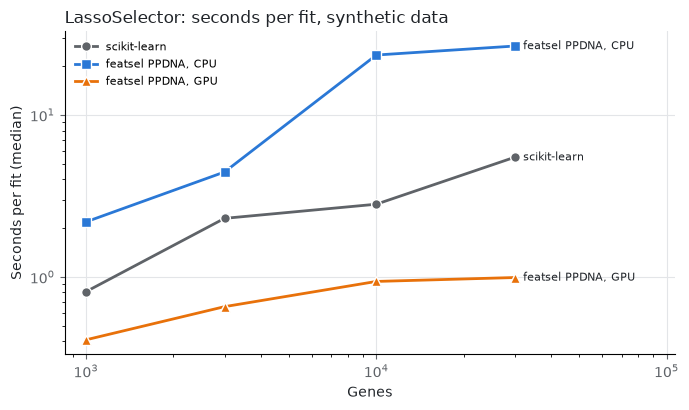

In [4]:
fig = benchmark.plot(table, f"{NAME}: seconds per fit, synthetic data")

## 2. SCAN-B, the five PAM50 tasks

Loading GSE96058 takes about a minute; the first run downloads it (592 MB).

In [5]:
from featsel_datasets.scanb_gse96058.featsel_view import load_xy

X_df, y_df = load_xy()
X = StandardScaler().fit_transform(X_df.to_numpy(dtype=np.float32)).astype(np.float32)
print(f"{X.shape[0]} patients x {X.shape[1]} genes")

rows = []
for task, y_task in build_tasks(y_df.to_numpy()):
    positive = y_task != 'rest'
    part = benchmark.benchmark(NAME, X, positive.astype(int), n_genes=(X.shape[1],))
    part.insert(0, 'task', task)
    part.insert(1, 'n_positive', int(positive.sum()))
    rows.append(part)
scanb = pd.concat(rows, ignore_index=True)
scanb.to_csv(OUT / f'{NAME}_scanb.csv', index=False)
environment.write_json((OUT / f'{NAME}_scanb.csv').with_suffix('.json'), selector=NAME,
                       params=benchmark.PARAMS[NAME], n_patients=int(X.shape[0]),
                       dataset='SCAN-B GSE96058, PAM50 one-vs-rest, standardized')
scanb.round(4)

2976 patients x 28552 genes


,task,n_positive,variant,device,n_genes,n_patients,fits,median_s,min_s,max_s,n_selected,reproducible,jaccard_vs_original
0,ovr_Basal,308,scikit-learn,cpu,28552,2976,3,4.2861,4.2860,4.2862,330,True,1.0000
1,ovr_Basal,308,"featsel PPDNA, CPU",cpu,28552,2976,3,4.5205,4.5194,4.5215,196,True,0.5516
2,ovr_Basal,308,"featsel PPDNA, GPU",cuda,28552,2976,3,0.7042,0.7030,0.7054,196,True,0.5516
3,ovr_Her2,297,scikit-learn,cpu,28552,2976,3,4.8179,4.6119,5.0239,571,True,1.0000
4,ovr_Her2,297,"featsel PPDNA, CPU",cpu,28552,2976,3,15.3362,14.8230,15.8494,430,True,0.6852
5,ovr_Her2,297,"featsel PPDNA, GPU",cuda,28552,2976,3,0.9776,0.9362,1.0191,430,True,0.6852
6,ovr_LumA,1502,scikit-learn,cpu,28552,2976,3,5.3353,5.2833,5.3872,1600,True,1.0000
7,ovr_LumA,1502,"featsel PPDNA, CPU",cpu,28552,2976,3,8.8490,8.8165,8.8815,906,True,0.5078
8,ovr_LumA,1502,"featsel PPDNA, GPU",cuda,28552,2976,3,1.3386,1.3285,1.3487,907,True,0.5084
9,ovr_LumB,669,scikit-learn,cpu,28552,2976,3,5.4901,5.4196,5.5607,1029,True,1.0000


In [6]:
verdict(scanb, 'task')

   ovr_Basal: featsel PPDNA, CPU 4.52 s, liblinear 4.29 s -> 1.1x slower; reproducible True, Jaccard 0.552
   ovr_Basal: featsel PPDNA, GPU 0.70 s, liblinear 4.29 s -> 6.1x faster; reproducible True, Jaccard 0.552
    ovr_Her2: featsel PPDNA, CPU 15.34 s, liblinear 4.82 s -> 3.2x slower; reproducible True, Jaccard 0.685
    ovr_Her2: featsel PPDNA, GPU 0.98 s, liblinear 4.82 s -> 4.9x faster; reproducible True, Jaccard 0.685
    ovr_LumA: featsel PPDNA, CPU 8.85 s, liblinear 5.34 s -> 1.7x slower; reproducible True, Jaccard 0.508
    ovr_LumA: featsel PPDNA, GPU 1.34 s, liblinear 5.34 s -> 4.0x faster; reproducible True, Jaccard 0.508
    ovr_LumB: featsel PPDNA, CPU 31.65 s, liblinear 5.49 s -> 5.8x slower; reproducible True, Jaccard 0.582
    ovr_LumB: featsel PPDNA, GPU 1.32 s, liblinear 5.49 s -> 4.2x faster; reproducible True, Jaccard 0.585
  ovr_Normal: featsel PPDNA, CPU 5.21 s, liblinear 5.82 s -> 1.1x faster; reproducible True, Jaccard 0.881
  ovr_Normal: featsel PPDNA, GPU 0.